# ToysGroup · Modulo 3 · Python for Data Science

In questo notebook analizzo i dati di ToysGroup, un'azienda che distribuisce giocattoli attraverso una rete di rivenditori in diversi paesi europei. I dati sono in quattro file (`products.csv`, `regions.xlsx`, `sales.json`, `resellers.csv`) nella cartella `data/`.

| Task | Di cosa si occupa |
|---|---|
| 1 | Python di base (liste, dizionari, cicli, funzioni) |
| 2 | Lettura e ispezione dei dati con Pandas e NumPy |
| 3a · 3b · 3c | Dati mancanti, aggregazioni, merge, serie temporali |
| 4 | Grafici |
| 5 | Correlazione e regressione lineare |
| 6a · 6b | Previsione del churn e segmentazione con K-Means |
| 7 | Debugging, refactoring e versioning |

Si può eseguire tutto di fila (*Kernel → Restart & Run All*). Prima di ogni cella di codice c'è una cella Markdown con il numero del task e la risposta richiesta.

### Setup · librerie e percorso dei dati
Importo le librerie che servono e indico dove si trovano i dati: la cartella `data/` se c'è, altrimenti la cartella del notebook.

In [1]:
import math
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data") if Path("data").is_dir() else Path(".")
print("Cartella dati:", DATA_DIR.resolve())

Cartella dati: C:\Users\maste\OneDrive\Desktop\epicod Phyton\toysgroup\data


### Due piccole funzioni di supporto
Mi servono solo per scrivere gli importi in euro (`1.234 €`) e per avere i nomi dei mesi in italiano nei titoli dei grafici.

In [2]:
MESI = ["gennaio", "febbraio", "marzo", "aprile", "maggio", "giugno",
        "luglio", "agosto", "settembre", "ottobre", "novembre", "dicembre"]

def euro(valore, decimali=0):
    """Formatta un importo con il punto come separatore delle migliaia: 12345.6 -> '12.346 €'."""
    testo = f"{valore:,.{decimali}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"{testo} €"

---
## Task 1 · Python di base sui dati forniti
*Python for Data Science · Parti 1 e 2*

**Vincolo:** Pandas lo uso solo per leggere i file. Somme, conteggi e classificazioni li faccio con liste, dizionari, cicli e funzioni di Python.

### Task 1 · punto 1 — Lettura e strutture dati
Leggo `products.csv` e `sales.json` e li trasformo con `.to_dict(orient="records")` in liste di dizionari. Poi creo `regions` come dizionario `{RegionID: (State, SalesRegion)}` e il set delle categorie.

In [3]:
prodotti = pd.read_csv(DATA_DIR / "products.csv").to_dict(orient="records")
vendite = pd.read_json(DATA_DIR / "sales.json").to_dict(orient="records")
regioni_raw = pd.read_excel(DATA_DIR / "regions.xlsx").to_dict(orient="records")

regions = {r["RegionID"]: (r["State"], r["SalesRegion"]) for r in regioni_raw}
categorie = {p["Category"] for p in prodotti}

print("Prodotti (len):", len(prodotti))
print("Vendite  (len):", len(vendite))
print("Regions (dizionario):")
for chiave, valore in regions.items():
    print("  ", chiave, "->", valore)
print("Categorie (set):", categorie)

Prodotti (len): 12
Vendite  (len): 2000
Regions (dizionario):
   1 -> ('Italia', 'Sud Europa')
   2 -> ('Francia', 'Sud Europa')
   3 -> ('Spagna', 'Sud Europa')
   4 -> ('Germania', 'Centro Europa')
   5 -> ('Austria', 'Centro Europa')
   6 -> ('Svizzera', 'Centro Europa')
   7 -> ('Svezia', 'Nord Europa')
   8 -> ('Norvegia', 'Nord Europa')
   9 -> ('Danimarca', 'Nord Europa')
Categorie (set): {'Giochi da tavolo', 'Giocattoli', 'Outdoor'}


### Task 1 · punto 2 — Fascia di prezzo
Assegno a ogni prodotto la fascia: **Bassa** sotto 20 €, **Media** fino a 60 €, **Alta** oltre 60 €. In una list comprehension non si può scrivere un `elif`, quindi metto l'`if/elif/else` in una piccola funzione e la richiamo dentro la comprehension.

In [4]:
def assegna_fascia(prezzo):
    """Restituisce la fascia di prezzo: Bassa (<20), Media (20-60), Alta (>60)."""
    if prezzo < 20:
        return "Bassa"
    elif prezzo <= 60:
        return "Media"
    else:
        return "Alta"

prodotti = [{**p, "Fascia": assegna_fascia(p["ListPrice"])} for p in prodotti]

for p in prodotti:
    print(f"{p['ProductID']:>2}  {p['ProductName']:<18} {p['Category']:<16} {p['ListPrice']:>7.2f} €  -> {p['Fascia']}")

 1  Bici Junior        Outdoor           129.00 €  -> Alta
 2  Bici BMX           Outdoor           189.00 €  -> Alta
 3  Monopattino        Outdoor            79.00 €  -> Alta
 4  Pallone Calcio     Outdoor            19.90 €  -> Bassa
 5  Racchette Beach    Outdoor            14.50 €  -> Bassa
 6  Puzzle 1000        Giochi da tavolo   17.90 €  -> Bassa
 7  Gioco dell'Oca     Giochi da tavolo   12.50 €  -> Bassa
 8  Scacchi Legno      Giochi da tavolo   34.00 €  -> Media
 9  Costruzioni 500    Giocattoli         39.90 €  -> Media
10  Bambola Classica   Giocattoli         24.90 €  -> Media
11  Robot RC           Giocattoli         89.00 €  -> Alta
12  Macchinina RC      Giocattoli         59.00 €  -> Media


### Task 1 · punto 3 — La funzione `fatturato_categoria()`
Con un ciclo `for` somma `SalesAmount` delle vendite della categoria, salta i valori mancanti e restituisce il totale con `return`.

In [5]:
def fatturato_categoria(vendite, prodotti, categoria):
    """Somma SalesAmount delle vendite di una categoria, ignorando gli importi mancanti."""
    id_categoria = {p["ProductID"] for p in prodotti if p["Category"] == categoria}
    totale = 0.0
    for v in vendite:
        if v["ProductID"] not in id_categoria:
            continue
        importo = v["SalesAmount"]
        if importo is None or math.isnan(importo):
            continue
        totale += importo
    return totale

fatturato_per_categoria = {c: fatturato_categoria(vendite, prodotti, c) for c in sorted(categorie)}
for c, tot in fatturato_per_categoria.items():
    print(f"{c:<18} {euro(tot, 2):>16}")
print("Totale             ", euro(sum(fatturato_per_categoria.values()), 2).rjust(16))

Giocattoli             174.832,00 €
Giochi da tavolo        53.245,10 €
Outdoor                331.998,40 €
Totale                  560.075,50 €


### Task 1 · punto 4 — Quante transazioni servono per superare 10.000 €
Scorro le vendite nell'ordine del file (che è già in ordine di data) e sommo gli importi finché il totale non supera 10.000 €. Gli importi mancanti li salto. Alla fine mostro le prime cinque transazioni con `vendite[:5]`.

In [6]:
cumulato = 0.0
righe_lette = 0
transazioni_con_importo = 0

while cumulato <= 10000 and righe_lette < len(vendite):
    importo = vendite[righe_lette]["SalesAmount"]
    if importo is not None and not math.isnan(importo):
        cumulato += importo
        transazioni_con_importo += 1
    righe_lette += 1

print(f"Fatturato cumulato: {euro(cumulato, 2)}")
print(f"Righe lette: {righe_lette} (di cui con importo valido: {transazioni_con_importo})")
print("\nPrime cinque transazioni (vendite[:5]):")
for v in vendite[:5]:
    print(v)

Fatturato cumulato: 10.164,80 €
Righe lette: 56 (di cui con importo valido: 52)

Prime cinque transazioni (vendite[:5]):
{'SalesID': 1194, 'ProductID': 6, 'RegionID': 7, 'ResellerID': 283, 'SalesDate': '2023-01-01', 'Quantity': 4.0, 'SalesAmount': 71.6}
{'SalesID': 859, 'ProductID': 6, 'RegionID': 8, 'ResellerID': 28, 'SalesDate': '2023-01-02', 'Quantity': 7.0, 'SalesAmount': nan}
{'SalesID': 1747, 'ProductID': 12, 'RegionID': 3, 'ResellerID': 281, 'SalesDate': '2023-01-02', 'Quantity': 2.0, 'SalesAmount': 118.0}
{'SalesID': 279, 'ProductID': 3, 'RegionID': 7, 'ResellerID': 128, 'SalesDate': '2023-01-02', 'Quantity': 3.0, 'SalesAmount': nan}
{'SalesID': 1470, 'ProductID': 1, 'RegionID': 6, 'ResellerID': 137, 'SalesDate': '2023-01-04', 'Quantity': 4.0, 'SalesAmount': nan}


### Task 1 · Definizione richiesta — lista, tupla, set, dizionario
| Struttura | Si può modificare | Ordine | Duplicati | Come si accede | Dove l'ho usata |
|---|---|---|---|---|---|
| **Lista** `[ ]` | sì | sì | ammessi | con l'**indice** (`prodotti[0]`) | `prodotti`, `vendite` |
| **Tupla** `( )` | **no** | sì | ammessi | con l'**indice** | `(State, SalesRegion)` dentro `regions` |
| **Set** `{ }` | sì | **no** | **non ammessi** | senza indice, si controlla solo l'appartenenza (`in`) | `categorie` |
| **Dizionario** `{k: v}` | sì | sì (mantiene l'ordine di inserimento) | chiavi uniche, valori ripetibili | con la **chiave** (`regions[7]`) | `regions` |

In pratica: lista e tupla si leggono per posizione, ma la tupla non si può cambiare. Il set elimina i duplicati ed è comodo per controllare se un valore c'è. Il dizionario collega ogni chiave a un valore.

### Task 1 · Criterio di completamento — riepilogo
Qui riepilogo quello che chiede il criterio: `len()` della lista prodotti, il dizionario `regions`, il set delle categorie, la fascia di ogni prodotto e il fatturato per categoria calcolato con `fatturato_categoria()`. Quest'ultimo lo confronto più avanti con il Task 3b.

In [7]:
print("len(prodotti)      =", len(prodotti))
print("regions            =", regions)
print("categorie          =", categorie)
print("fasce assegnate    =", {p["ProductName"]: p["Fascia"] for p in prodotti})
print("fatturato categoria=", {c: round(v, 2) for c, v in fatturato_per_categoria.items()})

len(prodotti)      = 12
regions            = {1: ('Italia', 'Sud Europa'), 2: ('Francia', 'Sud Europa'), 3: ('Spagna', 'Sud Europa'), 4: ('Germania', 'Centro Europa'), 5: ('Austria', 'Centro Europa'), 6: ('Svizzera', 'Centro Europa'), 7: ('Svezia', 'Nord Europa'), 8: ('Norvegia', 'Nord Europa'), 9: ('Danimarca', 'Nord Europa')}
categorie          = {'Giochi da tavolo', 'Giocattoli', 'Outdoor'}
fasce assegnate    = {'Bici Junior': 'Alta', 'Bici BMX': 'Alta', 'Monopattino': 'Alta', 'Pallone Calcio': 'Bassa', 'Racchette Beach': 'Bassa', 'Puzzle 1000': 'Bassa', "Gioco dell'Oca": 'Bassa', 'Scacchi Legno': 'Media', 'Costruzioni 500': 'Media', 'Bambola Classica': 'Media', 'Robot RC': 'Alta', 'Macchinina RC': 'Media'}
fatturato categoria= {'Giocattoli': 174832.0, 'Giochi da tavolo': 53245.1, 'Outdoor': 331998.4}


---
## Task 2 · Lettura e ispezione dei dati
*Pandas & NumPy · Parte 1*

**Vincolo:** in questo task non modifico nessun DataFrame, faccio solo lettura, descrizione e selezione.

### Task 2 · punto 1 — Lettura e ispezione
Leggo i quattro file con `pd.read_csv()`, `pd.read_excel()` e `pd.read_json()`. Per ognuno guardo `.shape`, `.info()`, `.head()` e `.tail()`.

In [8]:
df_products = pd.read_csv(DATA_DIR / "products.csv")
df_regions = pd.read_excel(DATA_DIR / "regions.xlsx")
df_sales = pd.read_json(DATA_DIR / "sales.json")
df_resellers = pd.read_csv(DATA_DIR / "resellers.csv")

dataframes = {"products": df_products, "regions": df_regions,
              "sales": df_sales, "resellers": df_resellers}

for nome, df_ in dataframes.items():
    print("=" * 70)
    print(f"{nome}  ->  shape = {df_.shape}  (righe, colonne)")
    df_.info()
    print("\nhead():")
    display(df_.head())
    print("tail():")
    display(df_.tail())

products  ->  shape = (12, 4)  (righe, colonne)
<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    12 non-null     int64  
 1   ProductName  12 non-null     str    
 2   Category     12 non-null     str    
 3   ListPrice    12 non-null     float64
dtypes: float64(1), int64(1), str(2)
memory usage: 788.0 bytes

head():


,ProductID,ProductName,Category,ListPrice
0,1,Bici Junior,Outdoor,129.0
1,2,Bici BMX,Outdoor,189.0
2,3,Monopattino,Outdoor,79.0
3,4,Pallone Calcio,Outdoor,19.9
4,5,Racchette Beach,Outdoor,14.5


tail():


,ProductID,ProductName,Category,ListPrice
7,8,Scacchi Legno,Giochi da tavolo,34.0
8,9,Costruzioni 500,Giocattoli,39.9
9,10,Bambola Classica,Giocattoli,24.9
10,11,Robot RC,Giocattoli,89.0
11,12,Macchinina RC,Giocattoli,59.0


regions  ->  shape = (9, 3)  (righe, colonne)
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   RegionID     9 non-null      int64
 1   State        9 non-null      str  
 2   SalesRegion  9 non-null      str  
dtypes: int64(1), str(2)
memory usage: 515.0 bytes

head():


...

,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
1995,326,3,1,280,2025-12-27,4.0,316.0
1996,394,7,2,256,2025-12-29,5.0,62.5
1997,196,4,8,50,2025-12-29,5.0,99.5
1998,878,4,4,27,2025-12-30,8.0,159.2
1999,1278,9,5,57,2025-12-30,9.0,359.1


resellers  ->  shape = (300, 7)  (righe, colonne)
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ResellerID          300 non-null    int64  
 1   RegionID            300 non-null    int64  
 2   Ordini12m           300 non-null    int64  
 3   GiorniUltimoOrdine  300 non-null    int64  
 4   ScontoMedio         300 non-null    float64
 5   Reclami             300 non-null    int64  
 6   Churn               300 non-null    int64  
dtypes: float64(1), int64(6)
memory usage: 16.5 KB

head():


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
0,1,1,14,65,0.131,1,0
1,2,7,9,149,0.117,1,0
2,3,6,21,1,0.065,2,0
3,4,4,18,162,0.011,1,1
4,5,4,22,98,0.120,0,0


tail():


,ResellerID,RegionID,Ordini12m,GiorniUltimoOrdine,ScontoMedio,Reclami,Churn
295,296,5,18,145,0.218,1,0
296,297,8,17,104,0.048,0,0
297,298,4,16,141,0.055,2,0
298,299,3,13,113,0.164,0,0
299,300,1,12,116,0.072,0,0


### Task 2 · punto 2 — `.describe()` e calcolo con NumPy
Con `.describe()` trovo minimo, massimo e media di `Quantity` e `SalesAmount`. Poi converto le due colonne in array NumPy e calcolo il prezzo unitario di ogni vendita con una sola operazione (`SalesAmount / Quantity`), senza toccare il DataFrame.

In [9]:
colonne_num = ["Quantity", "SalesAmount"]
descrizione = df_sales[colonne_num].describe()
display(descrizione)

print("Minimo, massimo e media:")
for col in colonne_num:
    print(f"  {col:<12} min = {descrizione.loc['min', col]:>8.2f}   max = {descrizione.loc['max', col]:>8.2f}   media = {descrizione.loc['mean', col]:>8.2f}")

quantita = df_sales["Quantity"].to_numpy()
importi = df_sales["SalesAmount"].to_numpy()

prezzo_unitario = importi / quantita          # operazione vettoriale
print("\nPrezzo unitario: primi 5 valori =", np.round(prezzo_unitario[:5], 2))
print("Elementi dell'array:", prezzo_unitario.size, "| NaN (da dati mancanti):", int(np.isnan(prezzo_unitario).sum()))
print("Prezzo unitario medio (nanmean): %.2f €" % np.nanmean(prezzo_unitario))

,Quantity,SalesAmount
count,1900.000,1900.000
mean,4.966,294.777
std,2.207,305.261
min,1.000,12.500
25%,3.000,89.000
50%,5.000,177.000
75%,6.000,387.000
max,14.000,2457.000


Minimo, massimo e media:
  Quantity     min =     1.00   max =    14.00   media =     4.97
  SalesAmount  min =    12.50   max =  2457.00   media =   294.78

Prezzo unitario: primi 5 valori = [17.9  nan 59.   nan  nan]
Elementi dell'array: 2000 | NaN (da dati mancanti): 198
Prezzo unitario medio (nanmean): 58.80 €


### Task 2 · punto 3 — Selezioni con `.loc[]` e `.iloc[]`
- Con `.loc[]` e una maschera booleana prendo i prodotti della categoria **Outdoor** con `ListPrice` sopra i 30 €.
- Con `.iloc[]` prendo le righe da 10 a 19 e le prime tre colonne di `sales`.

In [10]:
categoria = "Outdoor"
maschera = (df_products["Category"] == categoria) & (df_products["ListPrice"] > 30)
prodotti_selezionati = df_products.loc[maschera, ["ProductName", "Category", "ListPrice"]]
print(f"Prodotti '{categoria}' con ListPrice > 30 €:")
display(prodotti_selezionati)

sales_iloc = df_sales.iloc[10:20, :3]
print("Selezione .iloc[10:20, :3] -> shape =", sales_iloc.shape)
display(sales_iloc)

Prodotti 'Outdoor' con ListPrice > 30 €:


,ProductName,Category,ListPrice
0,Bici Junior,Outdoor,129.0
1,Bici BMX,Outdoor,189.0
2,Monopattino,Outdoor,79.0


Selezione .iloc[10:20, :3] -> shape = (10, 3)


,SalesID,ProductID,RegionID
10,218,1,8
11,1136,1,9
12,1326,3,4
13,1063,9,7
14,1606,10,8
15,1283,12,1
16,98,3,4
17,156,6,8
18,1642,12,5
19,1644,4,7


### Task 2 · Definizione richiesta — Series e DataFrame, `.loc[]` e `.iloc[]`
- Una **Series** è una colonna: una sola dimensione, con indice e un unico tipo di dato. Un **DataFrame** è una tabella, cioè un insieme di Series con lo stesso indice, ognuna col suo tipo. `df["Category"]` è una Series, `df[["Category"]]` è un DataFrame.
- **`.loc[]`** seleziona per **etichetta** (nome di riga o colonna) o con una **maschera booleana**. Negli intervalli per etichetta l'ultimo estremo è **incluso**.
- **`.iloc[]`** seleziona per **posizione** (0, 1, 2, …) come gli slice di Python: l'ultimo estremo è **escluso**, quindi `10:20` dà 10 righe.

### Task 2 · Criterio di completamento — riepilogo
Per ogni DataFrame riporto righe, colonne, tipi e numero di valori non nulli. La selezione con `.iloc[]` deve dare **10 righe e 3 colonne**.

In [11]:
riepilogo = []
for nome, df_ in dataframes.items():
    riepilogo.append({"DataFrame": nome, "Righe": df_.shape[0], "Colonne": df_.shape[1],
                      "Tipi": ", ".join(sorted({str(t) for t in df_.dtypes})),
                      "Celle non nulle": int(df_.notna().sum().sum()),
                      "Celle nulle": int(df_.isna().sum().sum())})
display(pd.DataFrame(riepilogo))

print("Non nulli per colonna in sales:")
print(df_sales.notna().sum().to_string())
assert sales_iloc.shape == (10, 3)
print("\n.iloc[10:20, :3] ->", sales_iloc.shape, "OK")

,DataFrame,Righe,Colonne,Tipi,Celle non nulle,Celle nulle
0,products,12,4,"float64, int64, str",48,0
1,regions,9,3,"int64, str",27,0
2,sales,2000,7,"float64, int64, str",13800,200
3,resellers,300,7,"float64, int64",2100,0


Non nulli per colonna in sales:
SalesID        2000
ProductID      2000
RegionID       2000
ResellerID     2000
SalesDate      2000
Quantity       1900
SalesAmount    1900

.iloc[10:20, :3] -> (10, 3) OK


### Task 2 · Osservazioni sui dati
- `sales` ha **2000 righe e 7 colonne**; `Quantity` e `SalesAmount` hanno **100 valori mancanti ciascuna** (5%). Solo 2 righe hanno mancanti in entrambe le colonne, per questo il prezzo unitario ha 198 NaN. `products` (12 righe), `regions` (9) e `resellers` (300) **non hanno valori mancanti**.
- `Quantity`: minimo 1, massimo 14, media 4,97. `SalesAmount`: minimo 12,50 €, massimo 2.457,00 €, media 294,78 € (calcolate sui valori presenti). Prezzo unitario medio: 58,80 €.
- La selezione `.iloc[10:20, :3]` restituisce 10 righe e 3 colonne; i prodotti Outdoor sopra 30 € sono Bici Junior, Bici BMX e Monopattino.

---
## Task 3a · Dati mancanti, filtri e ordinamento
*Pandas & NumPy · Parte 2*

### Task 3a · punto 1 — Contare i NaN
Lavoro su una **copia** del DataFrame delle vendite (`sales`), così `df_sales` resta quello originale. Conto i NaN per colonna con `.isna().sum()` e calcolo la percentuale sul numero totale di righe.

In [12]:
sales = df_sales.copy()

nan_prima = sales.isna().sum()
tabella_nan = pd.DataFrame({"NaN prima": nan_prima,
                            "% prima": (nan_prima / len(sales) * 100).round(2)})
display(tabella_nan)

,NaN prima,% prima
SalesID,0,0.0
ProductID,0,0.0
RegionID,0,0.0
ResellerID,0,0.0
SalesDate,0,0.0
Quantity,100,5.0
SalesAmount,100,5.0


### Task 3a · punto 2 — Imputare `Quantity` ed eliminare i `SalesAmount` mancanti
- `Quantity` la riempio con la **mediana** usando `fillna()`. La mediana la calcolo sui valori presenti, prima del `fillna()`.
- Le righe senza `SalesAmount` le elimino con `dropna()`: l'importo è proprio il valore che voglio analizzare e non mi pare giusto inventarlo. Dichiaro anche quante righe vengono tolte.

In [13]:
mediana_quantity = sales["Quantity"].median()          # calcolata prima del fillna()
sales["Quantity"] = sales["Quantity"].fillna(mediana_quantity)

righe_prima = len(sales)
sales = sales.dropna(subset=["SalesAmount"]).reset_index(drop=True)
righe_rimosse = righe_prima - len(sales)

tabella_nan["NaN dopo"] = sales.isna().sum()
tabella_nan["% dopo"] = (tabella_nan["NaN dopo"] / len(sales) * 100).round(2)
display(tabella_nan)

print(f"Mediana di Quantity usata per l'imputazione: {mediana_quantity}")
print(f"Righe prima: {righe_prima} | righe dopo: {len(sales)} | righe eliminate: {righe_rimosse}")
assert sales["Quantity"].isna().sum() == 0 and sales["SalesAmount"].isna().sum() == 0

,NaN prima,% prima,NaN dopo,% dopo
SalesID,0,0.0,0,0.0
ProductID,0,0.0,0,0.0
RegionID,0,0.0,0,0.0
ResellerID,0,0.0,0,0.0
SalesDate,0,0.0,0,0.0
Quantity,100,5.0,0,0.0
SalesAmount,100,5.0,0,0.0


Mediana di Quantity usata per l'imputazione: 5.0
Righe prima: 2000 | righe dopo: 1900 | righe eliminate: 100


### Task 3a · punto 3 — `.query()` e `sort_values()`
Con `.query()` estraggo le transazioni con `SalesAmount` **sopra il 90° percentile** (`quantile(0.9)`) e le ordino per **data crescente** e **importo decrescente**.

In [14]:
soglia_p90 = sales["SalesAmount"].quantile(0.9)

top_vendite = (sales.query("SalesAmount > @soglia_p90")
                    .sort_values(["SalesDate", "SalesAmount"], ascending=[True, False]))

print(f"90° percentile di SalesAmount: {soglia_p90:.2f} €")
print(f"Transazioni sopra la soglia: {len(top_vendite)} su {len(sales)}")
top_vendite.head(10)

90° percentile di SalesAmount: 756.00 €
Transazioni sopra la soglia: 162 su 1900


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount
28,1045,2,4,82,2023-01-16,6.0,1134.0
45,1872,2,7,204,2023-01-25,5.0,945.0
48,1639,1,3,299,2023-01-27,9.0,1161.0
94,296,2,9,202,2023-02-25,5.0,945.0
109,1462,2,2,224,2023-03-03,5.0,945.0
112,1221,1,8,149,2023-03-05,8.0,1032.0
114,1753,2,8,151,2023-03-05,5.0,945.0
156,283,2,2,100,2023-03-30,11.0,2079.0
203,1679,1,4,22,2023-04-27,5.0,774.0
207,832,2,4,82,2023-04-28,6.0,1134.0


### Task 3a · Definizione richiesta — imputazione dei dati mancanti
**Imputare** vuol dire sostituire i valori mancanti con un valore stimato, per non perdere le righe.
- **Media**: va bene se la distribuzione è simmetrica e senza valori estremi. È sensibile agli outlier e riduce la varianza.
- **Mediana**: meglio quando la distribuzione è **asimmetrica** o ci sono outlier, perché gli estremi non la influenzano. L'ho scelta per `Quantity`.
- **Eliminare la riga**: ha senso quando il valore mancante è proprio quello che si vuole misurare (qui `SalesAmount`) o quando i mancanti sono pochi. Si perde informazione e, se i mancanti non sono casuali, si può distorcere l'analisi.

Effetto sulla distribuzione: con media o mediana il centro resta uguale ma i valori si **addensano** attorno ad esso (la varianza cala). Eliminando le righe la forma dei dati rimasti non cambia, ma il campione diventa più piccolo.

### Task 3a · Criterio di completamento — risposta
- **NaN prima del trattamento:** `Quantity` 100 (5,00%), `SalesAmount` 100 (5,00%), tutte le altre colonne 0. **Dopo:** 0 in ogni colonna (tabella sopra).
- `Quantity` imputata con la mediana **5,0**; **righe eliminate: 100** (da 2000 a 1900), quelle con `SalesAmount` mancante.
- Filtro e ordinamento: il 90° percentile di `SalesAmount` è **756 €** e le transazioni sopra soglia sono **162 su 1900**, ordinate per data crescente e importo decrescente (prime 10 righe con `.head(10)`).
- *Nota:* in tutte le righe complete vale `SalesAmount = Quantity × ListPrice`, quindi un `Quantity` mancante si potrebbe ricostruire in modo esatto come `SalesAmount / ListPrice`. Qui seguo la consegna (mediana), ma è un'alternativa più precisa.

---
## Task 3b · Aggregazioni e combinazione dei DataFrame
*Pandas & NumPy · Parte 2*

### Task 3b · punto 1 — Merge di `sales` con `products` e `regions`
Unisco con `merge()` su `ProductID` e `RegionID` usando `how="left"`, poi controllo che le righe siano ancora quelle di `sales`.

In [15]:
vendite_complete = (sales.merge(df_products, on="ProductID", how="left")
                         .merge(df_regions, on="RegionID", how="left"))

print("Righe sales:", len(sales), "| righe dopo il merge:", len(vendite_complete))
assert len(vendite_complete) == len(sales)

print("\nNaN nelle colonne arrivate dal merge (vendite senza corrispondenza):")
print(vendite_complete[["ProductName", "Category", "ListPrice", "State", "SalesRegion"]].isna().sum().to_string())
vendite_complete.head()

Righe sales: 1900 | righe dopo il merge: 1900

NaN nelle colonne arrivate dal merge (vendite senza corrispondenza):
ProductName    0
Category       0
ListPrice      0
State          0
SalesRegion    0


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion
0,1194,6,7,283,2023-01-01,4.0,71.6,Puzzle 1000,Giochi da tavolo,17.9,Svezia,Nord Europa
1,1747,12,3,281,2023-01-02,2.0,118.0,Macchinina RC,Giocattoli,59.0,Spagna,Sud Europa
2,947,7,8,166,2023-01-04,6.0,75.0,Gioco dell'Oca,Giochi da tavolo,12.5,Norvegia,Nord Europa
3,577,3,4,285,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Germania,Centro Europa
4,78,3,8,107,2023-01-04,3.0,237.0,Monopattino,Outdoor,79.0,Norvegia,Nord Europa


### Task 3b · punto 2 — `groupby()` e `agg()` per Category e SalesRegion
Calcolo fatturato totale, quantità totale e numero di transazioni, in ordine di fatturato decrescente.

In [16]:
def aggrega(df, chiave):
    """Fatturato, quantità e n. transazioni per la colonna `chiave`, ordinato per fatturato decrescente."""
    return (df.groupby(chiave)
              .agg(Fatturato=("SalesAmount", "sum"),
                   Quantita=("Quantity", "sum"),
                   Transazioni=("SalesID", "count"))
              .sort_values("Fatturato", ascending=False))

per_categoria = aggrega(vendite_complete, "Category")
per_regione = aggrega(vendite_complete, "SalesRegion")

print("Per Category:")
display(per_categoria)
print("Per SalesRegion:")
display(per_regione)

Per Category:


,Fatturato,Quantita,Transazioni
Category,,,
Outdoor,331998.4,3800.0,767
Giocattoli,174832.0,3225.0,644
Giochi da tavolo,53245.1,2416.0,489


Per SalesRegion:


,Fatturato,Quantita,Transazioni
SalesRegion,,,
Centro Europa,201062.2,3413.0,698
Nord Europa,190189.0,3175.0,633
Sud Europa,168824.3,2853.0,569


### Task 3b · punto 3 — Separare le vendite 2025 e ricomporle con `pd.concat()`
Filtro le vendite del 2025 (ricavo l'anno con `pd.to_datetime(...).dt.year`), le rimetto insieme alle altre con `pd.concat()` e controllo che il numero di righe torni uguale all'originale.

In [17]:
anno = pd.to_datetime(vendite_complete["SalesDate"]).dt.year

vendite_2025 = vendite_complete[anno == 2025]
vendite_altre = vendite_complete[anno != 2025]
ricomposte = pd.concat([vendite_2025, vendite_altre])

print(f"Vendite 2025: {len(vendite_2025)} | altre: {len(vendite_altre)} | somma: {len(vendite_2025) + len(vendite_altre)}")
print(f"Righe originali: {len(vendite_complete)} | righe dopo concat: {len(ricomposte)}")
assert len(vendite_2025) + len(vendite_altre) == len(vendite_complete) == len(ricomposte)
assert np.isclose(ricomposte["SalesAmount"].sum(), vendite_complete["SalesAmount"].sum())
print("Controllo righe e fatturato: OK")

Vendite 2025: 640 | altre: 1260 | somma: 1900
Righe originali: 1900 | righe dopo concat: 1900
Controllo righe e fatturato: OK


### Task 3b · Confronto con il Task 1
Il fatturato per categoria calcolato con la funzione Python `fatturato_categoria()` (Task 1) deve essere uguale a quello ottenuto con `groupby()` (Task 3b).

In [18]:
confronto = pd.DataFrame({"Task 1 · fatturato_categoria()": pd.Series(fatturato_per_categoria),
                          "Task 3b · groupby()": per_categoria["Fatturato"]})
confronto["Differenza"] = confronto["Task 1 · fatturato_categoria()"] - confronto["Task 3b · groupby()"]
display(confronto)
assert np.allclose(confronto["Differenza"], 0)
print("I due metodi coincidono per tutte le categorie.")

,Task 1 · fatturato_categoria(),Task 3b · groupby(),Differenza
Giocattoli,174832.0,174832.0,2.910e-11
Giochi da tavolo,53245.1,53245.1,1.455e-11
Outdoor,331998.4,331998.4,-2.328e-10


I due metodi coincidono per tutte le categorie.


### Task 3b · Definizione richiesta — `merge()`, `join()`, `concat()`
- **`merge()`** unisce due DataFrame usando una o più **colonne chiave**, come un JOIN in SQL. Con `how="left"` tiene tutte le righe di sinistra; con `how="inner"` scarta quelle senza corrispondenza.
- **`join()`** unisce due DataFrame usando il loro **indice**.
- **`concat()`** **accoda** i DataFrame uno sotto l'altro (`axis=0`) o uno accanto all'altro (`axis=1`), senza cercare corrispondenze tra chiavi.

**Da ricordare:** con `how="inner"` il merge scarta le vendite senza corrispondenza in `products` o `regions`; con `how="left"` le tiene con dei NaN, che si contano con `.isna().sum()`.

### Task 3b · Criterio di completamento — risposta
- **Righe dopo il merge: 1900**, uguali a quelle di `sales`; nessun NaN nelle colonne arrivate da `products` e `regions` (ogni vendita ha la sua anagrafica).
- **Categoria con il fatturato più alto: Outdoor, 331.998,40 €** (59% del totale di 560.075,50 €), seguita da Giocattoli (174.832,00 €) e Giochi da tavolo (53.245,10 €).
- Per area di vendita: Centro Europa 201.062,20 €, Nord Europa 190.189,00 €, Sud Europa 168.824,30 €.
- Il fatturato per categoria di `fatturato_categoria()` (Task 1) **coincide** con quello di `groupby()`. Il filtro 2025 (640 righe) più le altre (1260) ricompone le **1900** righe originali.

---
## Task 3c · Serie temporali di vendita
*Pandas & NumPy · Parte 2*

**Vincolo:** anno, mese e differenza in giorni si ricavano con l'accessor `.dt` e con operazioni tra date, non con operazioni sulle stringhe.

### Task 3c · punti 1 e 2 — Conversione in datetime e colonne Anno, Mese, GiornoSettimana
Converto `SalesDate` con `pd.to_datetime()`, controllo il tipo con `.dtypes` e ricavo anno, mese e giorno della settimana con `.dt` (0 = lunedì, 6 = domenica).

In [19]:
print("Tipo prima:", vendite_complete["SalesDate"].dtype)
vendite_complete["SalesDate"] = pd.to_datetime(vendite_complete["SalesDate"])
print("Tipo dopo: ", vendite_complete["SalesDate"].dtype)

vendite_complete["Anno"] = vendite_complete["SalesDate"].dt.year
vendite_complete["Mese"] = vendite_complete["SalesDate"].dt.month
vendite_complete["GiornoSettimana"] = vendite_complete["SalesDate"].dt.dayofweek   # 0 = lunedì

print("\nTipi delle colonne:")
print(vendite_complete.dtypes.to_string())
vendite_complete[["SalesDate", "Anno", "Mese", "GiornoSettimana"]].head()

Tipo prima: str
Tipo dopo:  datetime64[us]

Tipi delle colonne:
SalesID                     int64
ProductID                   int64
RegionID                    int64
ResellerID                  int64
SalesDate          datetime64[us]
Quantity                  float64
SalesAmount               float64
ProductName                   str
Category                      str
ListPrice                 float64
State                         str
SalesRegion                   str
Anno                        int32
Mese                        int32
GiornoSettimana             int32


,SalesDate,Anno,Mese,GiornoSettimana
0,2023-01-01,2023,1,6
1,2023-01-02,2023,1,0
2,2023-01-04,2023,1,2
3,2023-01-04,2023,1,2
4,2023-01-04,2023,1,2


### Task 3c · punto 3 — Fatturato mensile e variazione percentuale
Raggruppo per anno e mese con `groupby()` e calcolo la variazione percentuale rispetto al mese prima con `pct_change()`.

In [20]:
fatturato_mensile = (vendite_complete.groupby(["Anno", "Mese"])["SalesAmount"]
                     .sum().reset_index(name="Fatturato"))
fatturato_mensile["VariazionePct"] = fatturato_mensile["Fatturato"].pct_change() * 100
fatturato_mensile["Periodo"] = pd.to_datetime(dict(year=fatturato_mensile["Anno"],
                                                   month=fatturato_mensile["Mese"], day=1))

print("Righe della serie mensile:", len(fatturato_mensile))
print("Primo mese:", fatturato_mensile.loc[0, ["Anno", "Mese"]].tolist(),
      "| ultimo mese:", fatturato_mensile.iloc[-1][["Anno", "Mese"]].astype(int).tolist())
assert len(fatturato_mensile) == 36
display(fatturato_mensile.head(8))

riga_max = fatturato_mensile.loc[fatturato_mensile["Fatturato"].idxmax()]
mese_max, anno_max = MESI[int(riga_max["Mese"]) - 1], int(riga_max["Anno"])
print(f"\nMese con il fatturato massimo: {mese_max} {anno_max} ({euro(riga_max['Fatturato'], 2)})")

Righe della serie mensile: 36
Primo mese: [2023, 1] | ultimo mese: [2025, 12]


,Anno,Mese,Fatturato,VariazionePct,Periodo
0,2023,1,11499.8,NaN,2023-01-01
1,2023,2,9414.9,-18.130,2023-02-01
2,2023,3,14917.2,58.442,2023-03-01
3,2023,4,11077.9,-25.737,2023-04-01
4,2023,5,10806.7,-2.448,2023-05-01
5,2023,6,11637.3,7.686,2023-06-01
6,2023,7,10161.0,-12.686,2023-07-01
7,2023,8,15387.5,51.437,2023-08-01



Mese con il fatturato massimo: maggio 2025 (29.368,30 €)


### Task 3c · punto 4 — Colonna booleana `Recente`
`Recente` vale `True` se la vendita è avvenuta entro 180 giorni dall'ultima data del dataset. Sottraggo le date e prendo i giorni con `.dt.days`.

In [21]:
ultima_data = vendite_complete["SalesDate"].max()
vendite_complete["Recente"] = (ultima_data - vendite_complete["SalesDate"]).dt.days <= 180

print("Ultima data nel dataset:", ultima_data.date())
print("Conteggio Recente:")
print(vendite_complete["Recente"].value_counts().to_string())
print("Recente = True:", int(vendite_complete["Recente"].sum()))

Ultima data nel dataset: 2025-12-30
Conteggio Recente:
Recente
False    1585
True      315
Recente = True: 315


### Task 3c · Criterio di completamento — risposta
- `SalesDate` è di tipo **datetime64** (prima era stringa).
- La serie mensile ha **36 righe**, da gennaio 2023 a dicembre 2025.
- **Mese con il fatturato massimo: maggio 2025, 29.368,30 €.**
- Colonna `Recente` (ultima data del dataset: 30/12/2025): **315 vendite con `Recente = True`** e 1585 con `False`.

---
## Task 4 · Visualizzazione e storytelling
*Visualizzazione Custom*

**Come scelgo il grafico:** andamento nel tempo → linee; confronto tra categorie → barre; distribuzione → boxplot; relazione tra variabili → heatmap o scatter.
**Vincolo:** il titolo di ogni grafico dice il risultato, non l'argomento. Sotto ogni grafico c'è una cella Markdown di due frasi: la domanda di business e la risposta che si legge nel grafico.

### Task 4 · grafico 1 — Matplotlib: fatturato mensile (linee)
*Domanda:* come cambia il fatturato nel tempo e quando raggiunge il picco? Disegno una linea con titolo, assi con unità di misura (€) e il mese di picco evidenziato da un'annotazione.

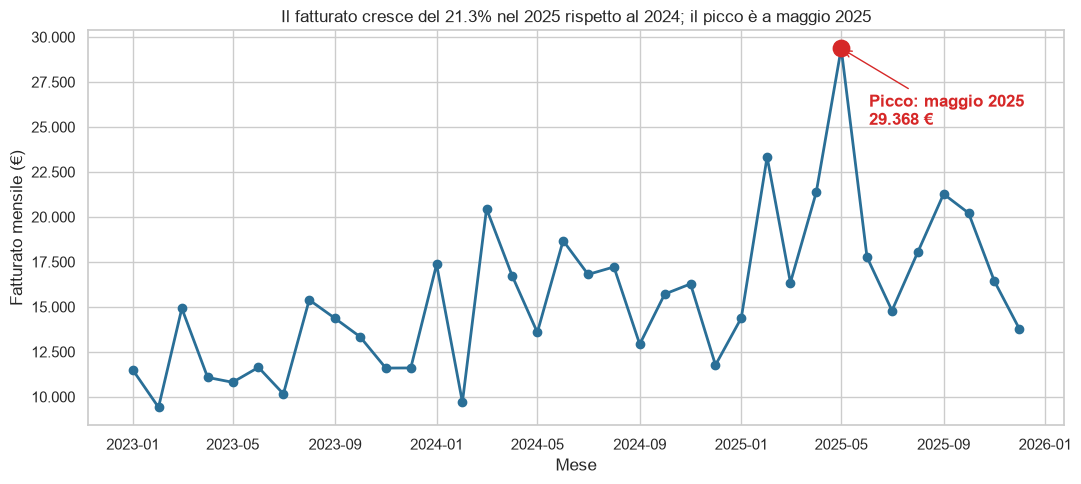

Fatturato annuo: 2023: 145.805 € | 2024: 187.175 € | 2025: 227.095 €


In [22]:
tot_anno = vendite_complete.groupby("Anno")["SalesAmount"].sum()
var_2025 = (tot_anno[2025] / tot_anno[2024] - 1) * 100
verbo = "cresce" if var_2025 >= 0 else "cala"

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(fatturato_mensile["Periodo"], fatturato_mensile["Fatturato"], marker="o", color="#2a6f97", linewidth=2)
ax.scatter([riga_max["Periodo"]], [riga_max["Fatturato"]], s=140, color="#d62828", zorder=3)
ax.annotate(f"Picco: {mese_max} {anno_max}\n{euro(riga_max['Fatturato'])}",
            xy=(riga_max["Periodo"], riga_max["Fatturato"]),
            xytext=(20, -55), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="#d62828"), color="#d62828", fontweight="bold")
ax.set_title(f"Il fatturato {verbo} del {abs(var_2025):.1f}% nel 2025 rispetto al 2024; il picco è a {mese_max} {anno_max}")
ax.set_xlabel("Mese")
ax.set_ylabel("Fatturato mensile (€)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
fig.tight_layout()
plt.show()
print(f"Fatturato annuo: " + " | ".join(f"{a}: {euro(v)}" for a, v in tot_anno.items()))

**Domanda di business e risposta.** Come evolve il fatturato mensile e quando tocca il massimo? Il fatturato annuo passa da 145.805 € (2023) a 187.175 € (2024) e 227.095 € (2025), cioè **+21,3% nel 2025**, con il picco a **maggio 2025** (29.368 €), pur con forti oscillazioni da un mese all'altro.

### Task 4 · grafico 2 — Seaborn: boxplot di `SalesAmount` per categoria
*Domanda:* come si distribuiscono gli importi delle vendite nelle varie categorie e quale ha le transazioni più alte? Uso un boxplot perché serve vedere la distribuzione.

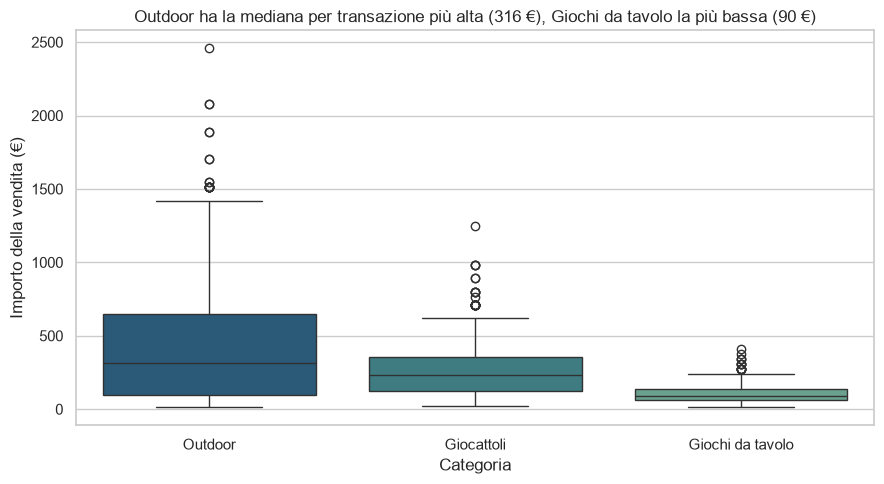

Mediana di SalesAmount per categoria:
Category
Outdoor             316.0
Giocattoli          236.0
Giochi da tavolo     89.5


In [23]:
mediane = vendite_complete.groupby("Category")["SalesAmount"].median().sort_values(ascending=False)
ordine = mediane.index.tolist()
cat_top, med_top = mediane.index[0], mediane.iloc[0]
cat_bassa, med_bassa = mediane.index[-1], mediane.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=vendite_complete, x="Category", y="SalesAmount", order=ordine, hue="Category",
            palette="crest", legend=False, ax=ax)
ax.set_title(f"{cat_top} ha la mediana per transazione più alta ({euro(med_top)}), {cat_bassa} la più bassa ({euro(med_bassa)})")
ax.set_xlabel("Categoria")
ax.set_ylabel("Importo della vendita (€)")
fig.tight_layout()
plt.show()
print("Mediana di SalesAmount per categoria:")
print(mediane.round(2).to_string())

**Domanda di business e risposta.** Quale categoria genera le vendite di importo più alto e quanto variano? **Outdoor** ha la mediana più alta (316 €) e la maggiore dispersione, con vendite fino a 2.457 €; Giocattoli ha mediana 236 € e Giochi da tavolo solo 90 € (89,50 €) con importi concentrati, in linea con i prezzi di listino.

### Task 4 · grafico 3 — Seaborn: heatmap di correlazione dei rivenditori
*Domanda:* quali caratteristiche dei rivenditori sono collegate tra loro e al churn? Uso una heatmap sulla matrice di correlazione delle variabili numeriche di `resellers`, lasciando fuori gli identificativi `ResellerID` e `RegionID`.

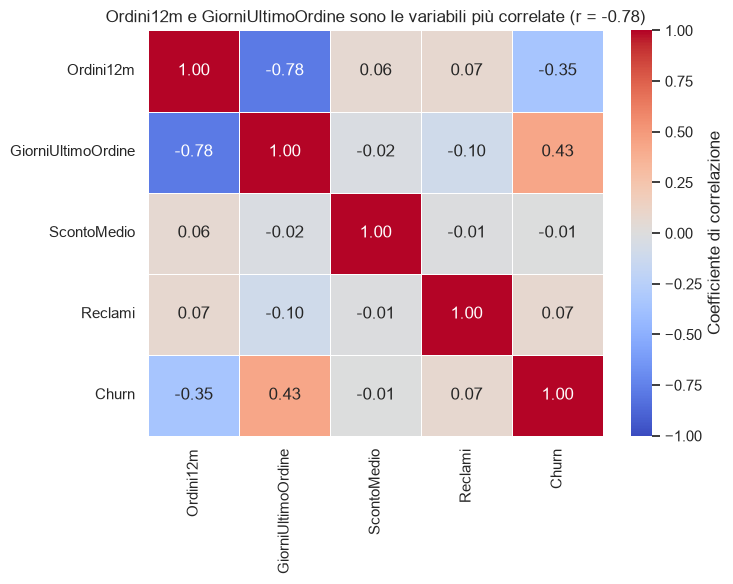

Correlazione con Churn:
GiorniUltimoOrdine    0.434
Ordini12m            -0.347
Reclami               0.073
ScontoMedio          -0.005


In [24]:
var_resellers = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami", "Churn"]
corr_res = df_resellers[var_resellers].corr()

coppie = corr_res.where(np.triu(np.ones(corr_res.shape, dtype=bool), k=1)).stack().dropna()
coppia_top = coppie.abs().idxmax()
r_top = corr_res.loc[coppia_top]

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_res, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            linewidths=0.5, cbar_kws={"label": "Coefficiente di correlazione"}, ax=ax)
ax.set_title(f"{coppia_top[0]} e {coppia_top[1]} sono le variabili più correlate (r = {r_top:.2f})")
fig.tight_layout()
plt.show()
print("Correlazione con Churn:")
print(corr_res["Churn"].drop("Churn").round(3).sort_values(key=np.abs, ascending=False).to_string())

**Domanda di business e risposta.** Quali caratteristiche dei rivenditori sono legate tra loro e al churn? `Ordini12m` e `GiorniUltimoOrdine` sono correlati negativamente (r = -0,78: chi ordina di più ha ordinato più di recente) e il churn è legato soprattutto a `GiorniUltimoOrdine` (r = +0,43) e a `Ordini12m` (r = -0,35), mentre `ScontoMedio` (-0,01) e `Reclami` (+0,07) sono quasi irrilevanti.

### Task 4 · grafico 4 (opzionale) — Plotly: fatturato per stato
Grafico a barre interattivo del fatturato per stato: passando il mouse sopra una barra compaiono quantità totale e numero di transazioni. Se `plotly` non è installato (`pip install plotly`) la cella lo segnala e il notebook va avanti.

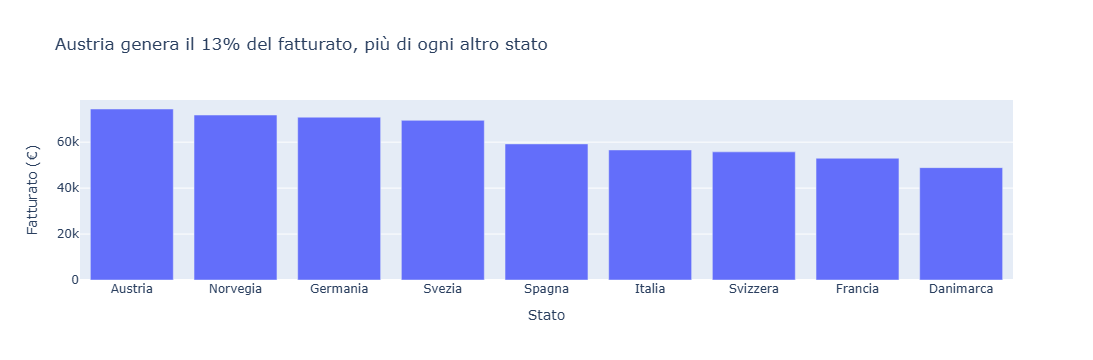

,State,Fatturato,Quantita,Transazioni
0,Austria,74426.4,1335.0,278
1,Norvegia,71802.4,1240.0,244
2,Germania,70867.6,1145.0,232
3,Svezia,69482.2,1144.0,230
4,Spagna,59227.8,1068.0,214
5,Italia,56601.6,908.0,184
6,Svizzera,55768.2,933.0,188
7,Francia,52994.9,877.0,171
8,Danimarca,48904.4,791.0,159


In [25]:
per_stato = aggrega(vendite_complete, "State").reset_index()
stato_top = per_stato.loc[0, "State"]
quota_top = per_stato.loc[0, "Fatturato"] / per_stato["Fatturato"].sum() * 100

try:
    import plotly.express as px
    fig_px = px.bar(per_stato, x="State", y="Fatturato", hover_data=["Quantita", "Transazioni"],
                    title=f"{stato_top} genera il {quota_top:.0f}% del fatturato, più di ogni altro stato",
                    labels={"State": "Stato", "Fatturato": "Fatturato (€)",
                            "Quantita": "Quantità totale", "Transazioni": "N. transazioni"})
    fig_px.show()
except ImportError:
    print("plotly non installato: grafico opzionale saltato (pip install plotly).")
per_stato

**Domanda di business e risposta.** Quali stati generano più fatturato? L'**Austria** è prima con 74.426 € (13% del totale), seguita da Norvegia (71.802 €) e Germania (70.868 €); la Danimarca è ultima con 48.904 €. *(Valori dalla tabella `per_stato`; il grafico interattivo richiede `plotly`.)*

---
## Task 5 · Correlazione e regressione lineare
*Correlazione e Regressione in Python*

### Task 5 · punto 1 — Correlazione tra fatturato, quantità e rivenditori attivi
Costruisco la serie mensile con `Fatturato`, `Quantita` (somma delle quantità) e `RivenditoriAttivi` (rivenditori diversi che hanno venduto nel mese). Poi calcolo la matrice di correlazione con `.corr()` e guardo qual è la coppia più correlata.

In [26]:
mensile = (vendite_complete.groupby(["Anno", "Mese"])
           .agg(Fatturato=("SalesAmount", "sum"),
                Quantita=("Quantity", "sum"),
                RivenditoriAttivi=("ResellerID", "nunique"))
           .reset_index())
mensile["IndiceMese"] = np.arange(1, len(mensile) + 1)      # 1 = gennaio 2023 ... 36 = dicembre 2025

corr = mensile[["Fatturato", "Quantita", "RivenditoriAttivi"]].corr()
display(corr)

coppie5 = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print("Coppie di variabili ordinate per correlazione:")
print(coppie5.sort_values(ascending=False).round(3).to_string())
print("\nCoppia più correlata:", coppie5.abs().idxmax(), "-> r =", round(coppie5[coppie5.abs().idxmax()], 3))

,Fatturato,Quantita,RivenditoriAttivi
Fatturato,1.000,0.868,0.556
Quantita,0.868,1.000,0.673
RivenditoriAttivi,0.556,0.673,1.000


Coppie di variabili ordinate per correlazione:
Fatturato  Quantita             0.868
Quantita   RivenditoriAttivi    0.673
Fatturato  RivenditoriAttivi    0.556

Coppia più correlata: ('Fatturato', 'Quantita') -> r = 0.868


### Task 5 · punto 2 — Regressione semplice e multipla
Dopo `train_test_split(test_size=0.2, random_state=42)` stimo con `LinearRegression`:
- un modello **semplice**: fatturato in funzione dell'indice del mese;
- un modello **multiplo**: fatturato in funzione di indice del mese, quantità e rivenditori attivi.

Per confrontarli ad armi pari uso lo stesso gruppo di mesi per il train e lo stesso per il test.

In [27]:
y = mensile["Fatturato"]
X_semplice = mensile[["IndiceMese"]]
X_multipla = mensile[["IndiceMese", "Quantita", "RivenditoriAttivi"]]

idx_train, idx_test = train_test_split(mensile.index, test_size=0.2, random_state=42)
print(f"Mesi in train: {len(idx_train)} | mesi in test: {len(idx_test)}")

modello_semplice = LinearRegression().fit(X_semplice.loc[idx_train], y.loc[idx_train])
modello_multiplo = LinearRegression().fit(X_multipla.loc[idx_train], y.loc[idx_train])

Mesi in train: 28 | mesi in test: 8


### Task 5 · punto 3 — Coefficienti, intercetta e R² su train e test
Metto in un'unica tabella `coef_`, `intercept_` e R² su train e test dei due modelli.

In [28]:
def riga_modello(nome, modello, X):
    """Riga della tabella comparativa: intercetta, coefficienti, R² su train e test."""
    riga = {"Modello": nome, "Intercetta": modello.intercept_}
    for col, coef in zip(X.columns, modello.coef_):
        riga[f"coef_{col}"] = coef
    riga["R² train"] = modello.score(X.loc[idx_train], y.loc[idx_train])
    riga["R² test"] = modello.score(X.loc[idx_test], y.loc[idx_test])
    return riga

tabella_modelli = pd.DataFrame([riga_modello("Semplice", modello_semplice, X_semplice),
                                riga_modello("Multipla", modello_multiplo, X_multipla)]).set_index("Modello")
display(tabella_modelli.round(4))

coef_mese = modello_semplice.coef_[0]
print(f"Coefficiente dell'indice del mese (modello semplice): {coef_mese:+.2f} € per mese")

,Intercetta,coef_IndiceMese,R² train,R² test,coef_Quantita,coef_RivenditoriAttivi
Modello,,,,,,
Semplice,10602.529,303.577,0.477,-1.879,NaN,NaN
Multipla,6323.673,-78.105,0.836,-0.415,85.305,-229.355


Coefficiente dell'indice del mese (modello semplice): +303.58 € per mese


### Task 5 · punto 3 (opzionale) — Previsione dei tre mesi successivi
Con il modello semplice prevedo il fatturato di gennaio, febbraio e marzo 2026 (indici 37, 38 e 39).

In [29]:
mesi_futuri = pd.DataFrame({"IndiceMese": [37, 38, 39]})
previsioni = modello_semplice.predict(mesi_futuri)

for nome_mese, valore in zip(["gennaio 2026", "febbraio 2026", "marzo 2026"], previsioni):
    print(f"{nome_mese:<14} fatturato previsto: {euro(valore)}")

gennaio 2026   fatturato previsto: 21.835 €
febbraio 2026  fatturato previsto: 22.138 €
marzo 2026     fatturato previsto: 22.442 €


### Task 5 · Definizione richiesta — R² e causalità
L'**R²** (coefficiente di determinazione) dice **quanta parte della variabilità** della variabile da spiegare il modello riesce a riprodurre. Sui dati di training, in un modello con intercetta, va **da 0 a 1**: 0 vuol dire che il modello non spiega niente più della media, 1 che spiega tutto. Sul **test** può diventare **negativo**, se il modello prevede peggio della semplice media.

Un R² o una correlazione alti **non dimostrano un rapporto di causa-effetto**: dicono solo che due grandezze si muovono insieme. Può esserci una terza variabile in comune, un trend condiviso o semplicemente il caso (con 36 mesi il campione è piccolo). Qui, per esempio, il fatturato dipende per costruzione dalla quantità venduta (importo = quantità × prezzo), quindi la loro correlazione è quasi ovvia.

### Task 5 · Criterio di completamento — risposta
**Correlazione.** La coppia più correlata è **fatturato–quantità** (r = 0,87), poi quantità–rivenditori attivi (0,67) e fatturato–rivenditori attivi (0,56).

**Tabella comparativa dei modelli** (28 mesi in train, 8 in test):

| Modello | Intercetta | Coefficienti | R² train | R² test |
|---|---|---|---|---|
| Semplice (indice del mese) | 10.602,53 | indice mese **+303,58** | 0,477 | **-1,879** |
| Multipla (indice, quantità, rivenditori) | 6.323,67 | indice mese -78,11; quantità +85,31; rivenditori attivi -229,36 | 0,836 | **-0,415** |

**Previsione con il modello semplice:** gennaio 2026 **21.835 €**, febbraio 2026 **22.138 €**, marzo 2026 **22.442 €**.

**Interpretazione.** Il coefficiente dell'indice del mese indica una crescita media di circa **+303,58 € per mese**.

**Attenzione ai limiti.** L'R² sul test è **negativo** in entrambi i modelli: sugli 8 mesi di test prevedono peggio della semplice media. Con soli 36 mesi, una forte variabilità mensile e uno split casuale (non cronologico) il modello lineare sul solo trend non è affidabile; la regressione multipla migliora sul train (0,84) ma non generalizza. Nel modello multiplo i segni negativi di indice del mese e rivenditori attivi derivano dalla forte correlazione tra le variabili esplicative (multicollinearità) e non vanno letti come effetti causali. Le tre previsioni sono quindi solo indicative.

---
## Task 6a · Classificazione del churn dei rivenditori
*Machine Learning: principi e cenni pratici*

### Task 6a · punto 1 — X, y, split stratificato e StandardScaler
`X` contiene `Ordini12m`, `GiorniUltimoOrdine`, `ScontoMedio` e `Reclami`; `y` è `Churn`. Faccio lo split con `stratify=y`, così train e test hanno la stessa quota di churn. Lo `StandardScaler` lo adatto (`fit`) **solo sul training**, per non far passare informazioni del test nel training (*data leakage*).

In [30]:
feature = ["Ordini12m", "GiorniUltimoOrdine", "ScontoMedio", "Reclami"]
X = df_resellers[feature]
y = df_resellers["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler().fit(X_train)            # fit solo sul training
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Quota di churn: totale {y.mean():.3f} | train {y_train.mean():.3f} | test {y_test.mean():.3f}")

Train: (240, 4) | Test: (60, 4)
Quota di churn: totale 0.237 | train 0.237 | test 0.233


### Task 6a · punto 2 — Regressione logistica e matrici di confusione
Addestro la `LogisticRegression` e ricavo le classi previste (`predict()`, che usa la soglia 0,5) e le probabilità di churn (`predict_proba()`). Costruisco la matrice di confusione con soglia **0,5** e con soglia **0,3**, cioè considerando churn chi ha probabilità `>= soglia`.

In [31]:
logit = LogisticRegression(random_state=42).fit(X_train_s, y_train)

y_pred_default = logit.predict(X_test_s)                 # soglia implicita 0,5
proba_test = logit.predict_proba(X_test_s)[:, 1]         # probabilità di Churn = 1
assert ((proba_test > 0.5).astype(int) == y_pred_default).all()

soglie = [0.5, 0.3]
previsioni_soglia = {s: (proba_test >= s).astype(int) for s in soglie}

etichette = ["Reale: resta (0)", "Reale: churn (1)"]
colonne = ["Previsto: resta (0)", "Previsto: churn (1)"]
for s in soglie:
    print(f"Matrice di confusione · soglia {s}")
    display(pd.DataFrame(confusion_matrix(y_test, previsioni_soglia[s], labels=[0, 1]), index=etichette, columns=colonne))

Matrice di confusione · soglia 0.5


,Previsto: resta (0),Previsto: churn (1)
Reale: resta (0),42,4
Reale: churn (1),10,4


Matrice di confusione · soglia 0.3


,Previsto: resta (0),Previsto: churn (1)
Reale: resta (0),36,10
Reale: churn (1),4,10


### Task 6a · punto 3 — Accuracy, Precision, Recall e baseline
Calcolo Accuracy, Precision e Recall per le due soglie e confronto l'Accuracy con la **baseline** "Churn = 0 per tutti", che non individua nessun rivenditore perso.

In [32]:
baseline_accuracy = accuracy_score(y_test, np.zeros_like(y_test))

righe = []
for s in soglie:
    p = previsioni_soglia[s]
    righe.append({"Soglia": s,
                  "Accuracy": accuracy_score(y_test, p),
                  "Precision": precision_score(y_test, p, zero_division=0),
                  "Recall": recall_score(y_test, p),
                  "Previsti churn": int(p.sum())})
metriche = pd.DataFrame(righe).set_index("Soglia")
display(metriche.round(3))
print(f"Baseline (Churn = 0 per tutti): Accuracy = {baseline_accuracy:.3f}, Recall = 0.000")

,Accuracy,Precision,Recall,Previsti churn
Soglia,,,,
0.5,0.767,0.5,0.286,8
0.3,0.767,0.5,0.714,20


Baseline (Churn = 0 per tutti): Accuracy = 0.767, Recall = 0.000


### Task 6a · punto 4 — Train e test: underfitting, buon adattamento o overfitting
Confronto Accuracy e Recall su train e test per le due soglie e calcolo anche l'AUC con `roc_auc_score()` (opzionale).

In [33]:
proba_train = logit.predict_proba(X_train_s)[:, 1]

righe = []
for s in soglie:
    p_tr, p_te = (proba_train >= s).astype(int), (proba_test >= s).astype(int)
    righe.append({"Soglia": s,
                  "Accuracy train": accuracy_score(y_train, p_tr), "Accuracy test": accuracy_score(y_test, p_te),
                  "Recall train": recall_score(y_train, p_tr), "Recall test": recall_score(y_test, p_te)})
confronto_tt = pd.DataFrame(righe).set_index("Soglia")
confronto_tt["Gap Accuracy"] = confronto_tt["Accuracy train"] - confronto_tt["Accuracy test"]
confronto_tt["Gap Recall"] = confronto_tt["Recall train"] - confronto_tt["Recall test"]
display(confronto_tt.round(3))

print(f"AUC test : {roc_auc_score(y_test, proba_test):.3f}")
print(f"AUC train: {roc_auc_score(y_train, proba_train):.3f}")
print("\nCoefficienti (feature standardizzate):")
print(pd.Series(logit.coef_[0], index=feature).round(3).to_string())

,Accuracy train,Accuracy test,Recall train,Recall test,Gap Accuracy,Gap Recall
Soglia,,,,,,
0.5,0.775,0.767,0.316,0.286,0.008,0.03
0.3,0.742,0.767,0.754,0.714,-0.025,0.04


AUC test : 0.761
AUC train: 0.805

Coefficienti (feature standardizzate):
Ordini12m            -0.285
GiorniUltimoOrdine    1.069
ScontoMedio           0.022
Reclami               0.279


### Task 6a · Definizione richiesta — apprendimento supervisionato e non supervisionato
| | Supervisionato | Non supervisionato |
|---|---|---|
| **Dati richiesti** | esempi con le variabili X **e il target y** già noto (etichette) | solo le variabili X, **senza etichette** |
| **Obiettivo** | imparare il legame tra X e y per **prevedere** y su dati nuovi | trovare una **struttura nascosta** (gruppi, pattern) nei dati |
| **Esempio nel task** | **Regressione logistica sul churn** (Task 6a), con target `Churn` valutato con Accuracy e Recall | **K-Means** sui rivenditori (Task 6b), che li raggruppa per comportamento d'acquisto senza usare `Churn` |

**Da ricordare:** nel churn un falso negativo (un rivenditore perso che non individuo) costa più di un falso positivo. A parità di Accuracy conviene la soglia con il Recall più alto.

### Task 6a · Criterio di completamento — risposta
Test set: 60 rivenditori, di cui 14 in churn.

| Soglia | Accuracy | Precision | Recall | Matrice (VN · FP · FN · VP) |
|---|---|---|---|---|
| 0,5 | 0,767 | 0,500 | **0,286** | 42 · 4 · 10 · 4 |
| 0,3 | 0,767 | 0,500 | **0,714** | 36 · 10 · 4 · 10 |

**Baseline** (Churn = 0 per tutti): Accuracy **0,767**, Recall 0. L'Accuracy del modello è quindi **uguale alla baseline** e da sola non dice nulla; il valore del modello sta nel Recall.

**Soglia scelta: 0,3.** A parità di Accuracy e Precision il Recall passa da 0,286 a 0,714: il modello individua 10 rivenditori in churn su 14 invece di 4. Il prezzo sono 6 falsi positivi in più, accettabile perché un rivenditore perso e non individuato (falso negativo) costa più di una azione di retention inutile.

**Diagnosi train/test (soglia 0,3):** Accuracy 0,742 train / 0,767 test, Recall 0,754 train / 0,714 test, AUC 0,805 train / 0,761 test. La differenza è minima, quindi **buon adattamento, senza overfitting**; la capacità predittiva è moderata (AUC 0,76 sul test), perché le variabili spiegano solo in parte il churn. La variabile che pesa di più è `GiorniUltimoOrdine` (coefficiente +1,07).

---
## Task 6b · Segmentazione dei rivenditori con K-Means
*Machine Learning: principi e cenni pratici*

### Task 6b · punto 1 — Fatturato per rivenditore, standardizzazione e inerzia per k da 1 a 10
Calcolo il fatturato totale per rivenditore con `groupby()` e lo aggiungo ai dati dei rivenditori. Poi standardizzo `Ordini12m`, `GiorniUltimoOrdine` e fatturato (K-Means usa le distanze, quindi senza standardizzare peserebbe di più la variabile con i numeri più grandi) e calcolo `inertia_` per `k` da 1 a 10 con `KMeans(n_init=10, random_state=42)`.

In [34]:
fatturato_rivenditore = vendite_complete.groupby("ResellerID")["SalesAmount"].sum().rename("Fatturato")
rivenditori = df_resellers.merge(fatturato_rivenditore, on="ResellerID", how="left")
print("Rivenditori senza vendite nel dataset:", int(rivenditori["Fatturato"].isna().sum()))
rivenditori["Fatturato"] = rivenditori["Fatturato"].fillna(0)

var_cluster = ["Ordini12m", "GiorniUltimoOrdine", "Fatturato"]
Z = StandardScaler().fit_transform(rivenditori[var_cluster])

ks = list(range(1, 11))
inerzie = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z).inertia_ for k in ks]
tabella_gomito = pd.DataFrame({"k": ks, "inertia_": inerzie})
tabella_gomito["Riduzione %"] = tabella_gomito["inertia_"].pct_change().mul(-100)
display(tabella_gomito.round(2))

Rivenditori senza vendite nel dataset: 4


,k,inertia_,Riduzione %
0,1,900.00,NaN
1,2,433.73,51.81
2,3,319.22,26.40
3,4,257.17,19.44
4,5,225.59,12.28
5,6,198.58,11.98
6,7,180.66,9.02
7,8,164.77,8.79
8,9,149.72,9.13
9,10,137.03,8.48


### Task 6b · punto 2 — Metodo del gomito e assegnazione dei cluster
Per scegliere `k` uso il **metodo del gomito**: prendo il punto della curva più lontano dalla retta che unisce il primo e l'ultimo punto, cioè quello oltre il quale aggiungere cluster fa scendere poco l'inerzia. Poi assegno i cluster con `fit_predict()` in una nuova colonna.

k scelto con il metodo del gomito: 3


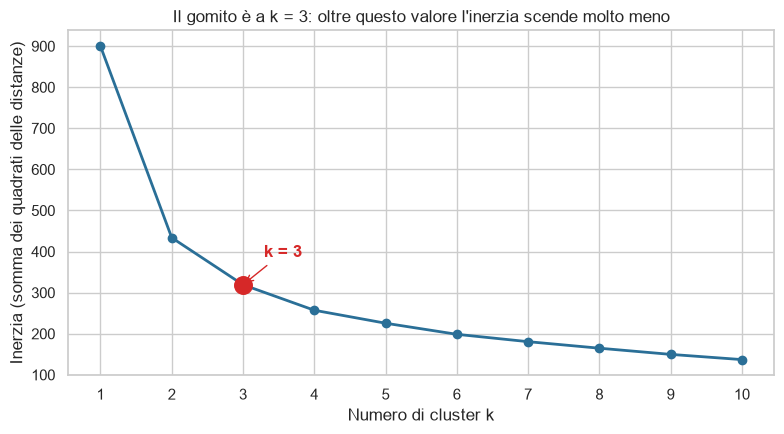

Cluster
0     95
1    137
2     68


In [35]:
# distanza di ogni punto (k, inerzia) dalla retta tra il primo e l'ultimo punto, su scale normalizzate
x_n = (np.array(ks) - ks[0]) / (ks[-1] - ks[0])
y_n = (np.array(inerzie) - inerzie[-1]) / (inerzie[0] - inerzie[-1])
distanza = np.abs(x_n + y_n - 1) / np.sqrt(2)           # retta: x + y = 1
k_scelto = int(ks[int(np.argmax(distanza))])
print("k scelto con il metodo del gomito:", k_scelto)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, inerzie, marker="o", color="#2a6f97", linewidth=2)
ax.scatter([k_scelto], [inerzie[k_scelto - 1]], s=160, color="#d62828", zorder=3)
ax.annotate(f"k = {k_scelto}", xy=(k_scelto, inerzie[k_scelto - 1]), xytext=(15, 20),
            textcoords="offset points", arrowprops=dict(arrowstyle="->", color="#d62828"),
            color="#d62828", fontweight="bold")
ax.set_xticks(ks)
ax.set_title(f"Il gomito è a k = {k_scelto}: oltre questo valore l'inerzia scende molto meno")
ax.set_xlabel("Numero di cluster k")
ax.set_ylabel("Inerzia (somma dei quadrati delle distanze)")
fig.tight_layout()
plt.show()

kmeans = KMeans(n_clusters=k_scelto, n_init=10, random_state=42)
rivenditori["Cluster"] = kmeans.fit_predict(Z)
print(rivenditori["Cluster"].value_counts().sort_index().to_string())

**Scelta di k.** L'inerzia scende da 900 (k = 1) a 433,7 (k = 2, -51,8%) e a 319,2 (k = 3, -26,4%); dopo k = 4 ogni cluster in più riduce l'inerzia meno del 13%. Il gomito non è netto, ma il punto più lontano dalla retta tra primo e ultimo valore è **k = 3**, che dà anche tre segmenti facili da interpretare e da usare commercialmente.

### Task 6b · punto 3 — Profilo dei cluster, nomi e quota di churn
Descrivo i cluster con `groupby()` sulle variabili **originali** (non standardizzate) e calcolo la quota di churn di ciascuno. Il nome di ogni segmento dipende dal suo profilo: giorni dall'ultimo ordine, ordini e fatturato rispetto alla media.

In [36]:
profilo = (rivenditori.groupby("Cluster")
           .agg(Rivenditori=("ResellerID", "count"),
                Ordini12m=("Ordini12m", "mean"),
                GiorniUltimoOrdine=("GiorniUltimoOrdine", "mean"),
                Fatturato=("Fatturato", "mean"),
                ScontoMedio=("ScontoMedio", "mean"),
                Reclami=("Reclami", "mean"),
                QuotaChurn=("Churn", "mean")))

def nomina_segmento(riga, medie):
    """Nome del segmento dal confronto del profilo medio con la media di tutti i rivenditori."""
    inattivo = riga["GiorniUltimoOrdine"] > medie["GiorniUltimoOrdine"]
    ordini_alti = riga["Ordini12m"] > medie["Ordini12m"]
    fatturato_alto = riga["Fatturato"] > medie["Fatturato"]
    if inattivo and not ordini_alti:
        return "Dormienti a rischio" if not fatturato_alto else "Grandi clienti in calo"
    if not inattivo and ordini_alti and fatturato_alto:
        return "Top attivi"
    if not inattivo and ordini_alti:
        return "Attivi e regolari"
    if not inattivo:
        return "Attivi occasionali"
    return "Intermedi"

medie_totali = rivenditori[var_cluster].mean()
profilo.insert(0, "Segmento", [nomina_segmento(r, medie_totali) for _, r in profilo.iterrows()])
profilo["QuotaChurn %"] = profilo["QuotaChurn"] * 100
display(profilo.round(2))

seg_top = profilo["QuotaChurn"].idxmax()
print(f"Segmento con il churn più alto: cluster {seg_top} '{profilo.loc[seg_top, 'Segmento']}' "
      f"({profilo.loc[seg_top, 'QuotaChurn %']:.1f}% di churn su {int(profilo.loc[seg_top, 'Rivenditori'])} rivenditori)")
print(f"Quota di churn media su tutti i rivenditori: {rivenditori['Churn'].mean() * 100:.1f}%")

,Segmento,Rivenditori,Ordini12m,GiorniUltimoOrdine,Fatturato,ScontoMedio,Reclami,QuotaChurn,QuotaChurn %
Cluster,,,,,,,,,
0,Attivi e regolari,95,19.58,48.35,1514.70,0.13,0.99,0.11,10.53
1,Dormienti a rischio,137,12.42,141.48,1288.47,0.12,0.99,0.39,39.42
2,Top attivi,68,21.66,45.90,3524.38,0.13,1.03,0.10,10.29


Segmento con il churn più alto: cluster 1 'Dormienti a rischio' (39.4% di churn su 137 rivenditori)
Quota di churn media su tutti i rivenditori: 23.7%


### Task 6b · Definizione richiesta — centroide, inerzia, niente colonna target né train/test
- **Centroide**: il punto medio (la media delle variabili) dei rivenditori di un cluster. K-Means assegna ogni punto al centroide più vicino e ricalcola i centroidi finché la soluzione non cambia più.
- **Inerzia** (`inertia_`): somma dei quadrati delle distanze tra ogni punto e il centroide del suo cluster. Misura quanto sono compatti i cluster e scende sempre quando `k` aumenta, per questo si cerca il "gomito" e non il valore minimo.
- **Perché K-Means non ha bisogno di una colonna target né della divisione train/test**: è un metodo **non supervisionato**, non deve prevedere nessuna etichetta, quindi non c'è un errore di previsione da misurare su dati mai visti. Descrive i dati che ha. `Churn` lo uso solo dopo, per interpretare i segmenti.

### Task 6b · Criterio di completamento — risposta
| Segmento | Rivenditori | Ordini12m | Giorni dall'ultimo ordine | Fatturato medio | Quota di churn |
|---|---|---|---|---|---|
| Attivi e regolari | 95 | 19,6 | 48 | 1.514,70 € | 10,5% |
| **Dormienti a rischio** | 137 | 12,4 | 141 | 1.288,47 € | **39,4%** |
| Top attivi | 68 | 21,7 | 46 | 3.524,38 € | 10,3% |

**Il segmento con il churn più alto è "Dormienti a rischio": 39,4%**, contro il 23,7% medio. Con 137 rivenditori e circa 54 persi su 71 totali, contiene circa tre quarti di tutto il churn. I "Top attivi" hanno oltre il doppio del fatturato medio degli altri segmenti e solo il 10,3% di churn. *(Quattro rivenditori non hanno vendite nel dataset e hanno fatturato 0. Il numero del cluster può cambiare con altre versioni di scikit-learn, i nomi dei segmenti no, perché sono assegnati dal profilo.)*

---
## Task 7 · Debugging, refactoring e versioning
*AI for Coding · AI ON*

Come assistente AI ho usato **Claude**. Per ognuno dei quattro frammenti riporto l'**errore originale**, la **causa**, la **versione corretta** e il **prompt usato**. Una correzione proposta dall'AI la accetto solo dopo averla eseguita nel notebook: per questo ogni caso ha una cella che riproduce il problema (quando si può) e una che esegue la versione corretta.

### Caso 1 · media del fatturato
**Codice originale**
```python
# Caso 1: media del fatturato
totale = 0
for v in sales["SalesAmount"]:
    totale += v
media = totale / len(sales)
```
**Prompt usato (Claude):** *«Questo codice calcola la media di SalesAmount con un ciclo for. Su sales.json con valori mancanti restituisce nan. Spiega la causa, dimmi se ci sono pratiche scorrette e proponi una versione corretta con Pandas.»*

**Causa:** nei dati grezzi `SalesAmount` ha dei `NaN`, e basta un `NaN` in `totale += v` per rendere NaN tutta la somma (il risultato è `nan`). In più dividere per `len(sales)` conta anche le righe senza importo, e il ciclo è una pratica scorretta: `Series.mean()` fa la stessa cosa in una riga, è più veloce e **salta i NaN**.

In [37]:
# Riproduzione dell'errore: sui dati grezzi (con NaN) la media originale è nan
totale = 0
for v in df_sales["SalesAmount"]:
    totale += v
media_originale = totale / len(df_sales)
print("Versione originale su dati grezzi:", media_originale)

# Anche saltando i NaN a mano, dividere per len() conta le righe senza importo e abbassa la media
somma_valida = df_sales["SalesAmount"].sum()
print("Somma / len(df_sales) (sbagliata):", round(somma_valida / len(df_sales), 4))

Versione originale su dati grezzi: nan
Somma / len(df_sales) (sbagliata): 280.0378


**Caso 1 · versione corretta (eseguita).** `Series.mean()` salta i NaN e divide per i soli valori presenti; sui dati puliti coincide con la media calcolata col ciclo.

In [38]:
# Versione corretta
media_corretta = df_sales["SalesAmount"].mean()          # salta i NaN e divide per i soli valori presenti
print("Media corretta (dati grezzi):", round(media_corretta, 4))

# Sui dati puliti del Task 3a la versione con ciclo e quella vettoriale coincidono
totale_pulito = 0
for v in sales["SalesAmount"]:
    totale_pulito += v
assert np.isclose(totale_pulito / len(sales), sales["SalesAmount"].mean())
print("Media sui dati puliti (Task 3a):", round(sales["SalesAmount"].mean(), 4))

Media corretta (dati grezzi): 294.7766
Media sui dati puliti (Task 3a): 294.7766


### Caso 2 · preparazione del modello
**Codice originale**
```python
# Caso 2: preparazione del modello
scaler = StandardScaler()
X_s = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = \
    train_test_split(X_s, y)
```
**Prompt usato (Claude):** *«Controlla questo codice di preparazione per un modello di classificazione. Dimmi se c'è un errore metodologico e riscrivilo correttamente per il caso del churn (X = variabili dei rivenditori, y = Churn).»*

**Causa:** è un caso di **data leakage**. Lo `StandardScaler` fa `fit_transform` su **tutto** il dataset *prima* della divisione, quindi media e deviazione standard tengono conto anche delle righe di test, che finiscono per influenzare il training. In più `train_test_split` è chiamato senza `random_state` (il risultato cambia a ogni esecuzione) e senza `stratify=y` (con un target sbilanciato train e test possono avere quote di churn diverse). **Correzione:** prima divido, poi adatto lo scaler **solo sul training** e lo applico al test.

In [39]:
# Riproduzione: lo scaler "vede" anche il test (media e deviazione standard calcolate su tutte le righe)
scaler_errato = StandardScaler().fit(X)
scaler_giusto = StandardScaler().fit(X_train)
confronto_scaler = pd.DataFrame({"media su TUTTO (errata)": scaler_errato.mean_,
                                 "media solo TRAIN (corretta)": scaler_giusto.mean_}, index=feature)
display(confronto_scaler.round(4))

,media su TUTTO (errata),media solo TRAIN (corretta)
Ordini12m,16.780,16.954
GiorniUltimoOrdine,90.323,89.496
ScontoMedio,0.128,0.132
Reclami,0.997,1.008


**Caso 2 · versione corretta (eseguita).** Prima si divide (stratificato, `random_state=42`), poi lo scaler è adattato solo sul training e applicato al test con `transform`.

In [40]:
# Versione corretta: prima split (stratificato e riproducibile), poi fit dello scaler solo sul training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)     # fit solo sul training
X_test_s = scaler.transform(X_test)           # sul test si applica soltanto transform

print("Forma train/test:", X_train_s.shape, X_test_s.shape)
print("Media delle feature nel train (≈ 0):", X_train_s.mean(axis=0).round(6))
print("Quota di churn train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Forma train/test: (240, 4) (60, 4)
Media delle feature nel train (≈ 0): [ 0. -0. -0.  0.]
Quota di churn train / test: 0.238 / 0.233


### Caso 3 · filtro vendite Bikes
**Codice originale**
```python
# Caso 3: filtro vendite Bikes
alte = df[df["SalesAmount"] > 500 and
          df["Category"] == "Bikes"]
print(alte.shape)
```
**Prompt usato (Claude):** *«Questo filtro Pandas dà un errore. Spiegami la causa e correggilo. Il DataFrame è quello delle vendite unite ai prodotti di ToysGroup: controlla anche che i valori filtrati esistano davvero.»*

**Causa:** ci sono due errori. (1) `and` non funziona con le Series di Pandas: Python prova a trasformare un'intera Series in `True`/`False` e dà `ValueError: The truth value of a Series is ambiguous`. Bisogna usare `&` o `|`, che lavorano elemento per elemento, con **ogni condizione tra parentesi** (`&` ha la precedenza su `>` e `==`). (2) La categoria `"Bikes"` **non c'è** nel dataset ToysGroup (le categorie sono Outdoor, Giochi da tavolo e Giocattoli), quindi anche con la sintassi giusta il filtro darebbe 0 righe.

In [41]:
df = vendite_complete          # vendite unite ai prodotti (Task 3b)

# Riproduzione dell'errore originale
try:
    alte = df[df["SalesAmount"] > 500 and df["Category"] == "Bikes"]
except ValueError as errore:
    print("ValueError:", errore)

# Sintassi corretta ma categoria inesistente -> filtro vuoto
vuoto = df[(df["SalesAmount"] > 500) & (df["Category"] == "Bikes")]
print("\nCon '&' ma categoria 'Bikes':", vuoto.shape, "| categorie presenti:", sorted(df["Category"].unique()))

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

Con '&' ma categoria 'Bikes': (0, 16) | categorie presenti: ['Giocattoli', 'Giochi da tavolo', 'Outdoor']


**Caso 3 · versione corretta (eseguita).** Operatore `&` con ogni condizione tra parentesi e una categoria presente nel dataset (Outdoor).

In [42]:
# Versione corretta: & con parentesi e una categoria presente nel dataset
alte = df[(df["SalesAmount"] > 500) & (df["Category"] == "Outdoor")]
print("Vendite Outdoor con SalesAmount > 500:", alte.shape)
alte.head()

Vendite Outdoor con SalesAmount > 500: (285, 16)


,SalesID,ProductID,RegionID,ResellerID,SalesDate,Quantity,SalesAmount,ProductName,Category,ListPrice,State,SalesRegion,Anno,Mese,GiornoSettimana,Recente
17,1799,2,7,234,2023-01-09,3.0,567.0,Bici BMX,Outdoor,189.0,Svezia,Nord Europa,2023,1,0,False
28,1045,2,4,82,2023-01-16,6.0,1134.0,Bici BMX,Outdoor,189.0,Germania,Centro Europa,2023,1,0,False
45,1872,2,7,204,2023-01-25,5.0,945.0,Bici BMX,Outdoor,189.0,Svezia,Nord Europa,2023,1,2,False
48,1639,1,3,299,2023-01-27,9.0,1161.0,Bici Junior,Outdoor,129.0,Spagna,Sud Europa,2023,1,4,False
53,207,1,6,26,2023-01-29,4.0,516.0,Bici Junior,Outdoor,129.0,Svizzera,Centro Europa,2023,1,6,False


### Caso 4 · funzione di report
**Codice originale**
```python
# Caso 4: funzione di report
def f(d, x):
    return d[d.iloc[:, 3] > x]\
           .iloc[:, 6].sum()
```
**Prompt usato (Claude):** *«Rifattorizza questa funzione: nomi non descrittivi, nessuna documentazione e colonne indicate con indici numerici. Dimmi cosa calcola davvero sul DataFrame delle vendite e riscrivila con nomi espliciti e docstring.»*

**Causa:** è una pratica scorretta di leggibilità e robustezza. Il nome `f` e i parametri `d` e `x` non dicono nulla, manca la docstring e le colonne sono scelte per **posizione** (`iloc[:, 3]`, `iloc[:, 6]`): se cambia l'ordine delle colonne il codice si rompe, o peggio calcola altro senza avvisare. Nel DataFrame `sales` la colonna 3 è `ResellerID` e la 6 è `SalesAmount`, quindi la funzione somma gli importi dei rivenditori con **ID maggiore di x**, e probabilmente l'idea era filtrare per quantità. La versione corretta usa **nomi di colonna espliciti** e dice cosa fa.

In [43]:
# Funzione originale (riprodotta): funziona, ma è opaca e dipende dalla posizione delle colonne
def f(d, x):
    return d[d.iloc[:, 3] > x].iloc[:, 6].sum()

print("Colonne di sales:", list(enumerate(sales.columns)))
print("f(sales, 5) =", round(f(sales, 5), 2), "-> filtra su", sales.columns[3], "e somma", sales.columns[6])

Colonne di sales: [(0, 'SalesID'), (1, 'ProductID'), (2, 'RegionID'), (3, 'ResellerID'), (4, 'SalesDate'), (5, 'Quantity'), (6, 'SalesAmount')]
f(sales, 5) = 551034.3 -> filtra su ResellerID e somma SalesAmount


**Caso 4 · versione corretta (eseguita).** Funzione con nome descrittivo, parametri chiari, docstring e colonne selezionate per nome: funziona anche se cambia l'ordine delle colonne.

In [44]:
# Versione corretta: nomi espliciti, colonne per nome, docstring
def fatturato_sopra_quantita(vendite, soglia_quantita):
    """Fatturato delle vendite con quantità superiore alla soglia.

    Parametri
    ---------
    vendite : DataFrame con le colonne 'Quantity' e 'SalesAmount'.
    soglia_quantita : numero; si considerano le vendite con Quantity > soglia_quantita.

    Restituisce
    -----------
    float : somma di SalesAmount delle vendite selezionate.
    """
    vendite_selezionate = vendite[vendite["Quantity"] > soglia_quantita]
    return vendite_selezionate["SalesAmount"].sum()

print("fatturato_sopra_quantita(sales, 5) =", round(fatturato_sopra_quantita(sales, 5), 2))
print("Stessa funzione su vendite_complete (colonne in ordine diverso):",
      round(fatturato_sopra_quantita(vendite_complete, 5), 2))
help(fatturato_sopra_quantita)

fatturato_sopra_quantita(sales, 5) = 275260.4
Stessa funzione su vendite_complete (colonne in ordine diverso): 275260.4
Help on function fatturato_sopra_quantita in module __main__:

fatturato_sopra_quantita(vendite, soglia_quantita)
    Fatturato delle vendite con quantità superiore alla soglia.

    Parametri
    ---------
    vendite : DataFrame con le colonne 'Quantity' e 'SalesAmount'.
    soglia_quantita : numero; si considerano le vendite con Quantity > soglia_quantita.

    Restituisce
    -----------
    float : somma di SalesAmount delle vendite selezionate.



### Task 7 · Criterio di completamento — risposta
| Caso | Errore originale | Causa | Correzione eseguita |
|---|---|---|---|
| 1 · media del fatturato | `nan` sui dati grezzi | `NaN` nella somma; divisione per `len()` che conta anche le righe senza importo; ciclo al posto di `.mean()` | `df_sales["SalesAmount"].mean()` = 294,78 € (coincide con la media sui dati puliti) |
| 2 · preparazione del modello | nessuna eccezione, errore metodologico | **data leakage**: `fit_transform` su tutto il dataset prima dello split; niente `random_state` né `stratify` | split stratificato e riproducibile, poi `fit` dello scaler solo sul train |
| 3 · filtro Bikes | `ValueError: The truth value of a Series is ambiguous` | `and` non vale per le Series; la categoria "Bikes" non esiste nel dataset | `(cond1) & (cond2)` con categoria "Outdoor": 285 righe |
| 4 · funzione di report | nessuna eccezione, pratica scorretta | nomi non descrittivi, niente docstring, colonne per posizione (`iloc[:, 3]` è `ResellerID`) | `fatturato_sopra_quantita(vendite, soglia_quantita)` con colonne per nome e docstring |

Le **quattro versioni corrette sono eseguite senza errori** in questo notebook; il Caso 4 usa nomi espliciti e docstring.